# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [11]:
!pip install matplotlib numpy pandas seaborn huggingface_hub scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 18.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 18.9 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]


In [36]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
import sklearn
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

sklearn.set_config(transform_output="pandas")

In [3]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data/zadanie-1/pendigits


In [34]:
def plot_confusion_matrix(y_test,y_pred):  
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title('Confusion Matrix')
    plt.xlabel('Przewidziana klasa')
    plt.ylabel('Prawdziwa klasa')
    plt.show()

## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [4]:
column_names = [f"{coord}{i}" for i in range(1, 9) for coord in ('x', 'y')] + ['digit']
df_train = pd.read_csv("data/zadanie-1/pendigits/pendigits-tra.csv", header=None, names=column_names)
df_test = pd.read_csv("data/zadanie-1/pendigits/pendigits-tes.csv", header=None, names=column_names)
df_train.info()
df_train.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 7494 entries, 0 to 7493
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   x1      7494 non-null   int64
 1   y1      7494 non-null   int64
 2   x2      7494 non-null   int64
 3   y2      7494 non-null   int64
 4   x3      7494 non-null   int64
 5   y3      7494 non-null   int64
 6   x4      7494 non-null   int64
 7   y4      7494 non-null   int64
 8   x5      7494 non-null   int64
 9   y5      7494 non-null   int64
 10  x6      7494 non-null   int64
 11  y6      7494 non-null   int64
 12  x7      7494 non-null   int64
 13  y7      7494 non-null   int64
 14  x8      7494 non-null   int64
 15  y8      7494 non-null   int64
 16  digit   7494 non-null   int64
dtypes: int64(17)
memory usage: 995.4 KB


,count,mean,std,min,25%,50%,75%,max
x1,7494.0,37.384307,33.322024,0.0,5.0,31.0,61.0,100.0
y1,7494.0,84.679343,16.848420,0.0,76.0,89.0,100.0,100.0
x2,7494.0,40.005604,26.256025,0.0,20.0,39.0,58.0,100.0
y2,7494.0,82.889512,19.638582,0.0,70.0,89.0,100.0,100.0
x3,7494.0,50.878303,34.927201,0.0,17.0,56.0,81.0,100.0
y3,7494.0,65.044436,27.377341,0.0,48.0,71.0,86.0,100.0
x4,7494.0,51.471844,30.680075,0.0,28.0,54.0,75.0,100.0
y4,7494.0,44.599680,30.659478,0.0,22.0,42.0,65.0,100.0
x5,7494.0,57.129971,33.680340,0.0,30.0,60.0,88.0,100.0
y5,7494.0,34.069122,27.459989,0.0,7.0,33.0,55.0,100.0


Text(0, 0.5, 'Liczba wystąpień')

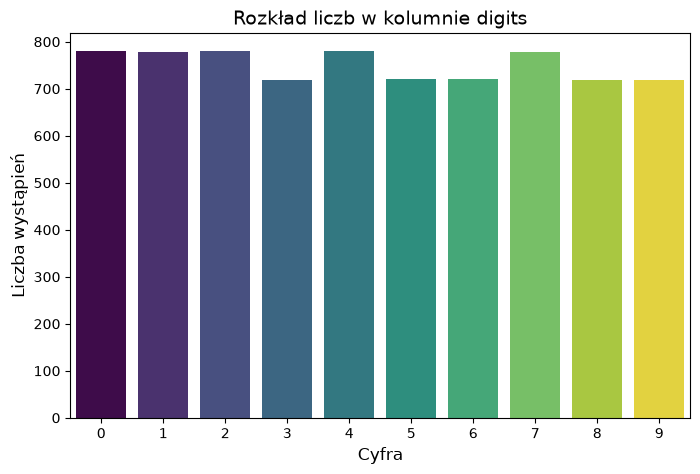

In [13]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_train, x='digit', palette='viridis', hue='digit', legend=False)
plt.title('Rozkład liczb w kolumnie digits', fontsize=14)
plt.xlabel('Cyfra', fontsize=12)
plt.ylabel('Liczba wystąpień', fontsize=12)

Zbiór danych skałda się jedynie z wartości numerycznych, nie ma brakujących wartości i outlierów - wszystkie współrzędne przyjmują wartości z zakresu 0...100. Rozkład klas jest symetryczny.
Korzystam ze skalera, by ujednolicić wariancję i zapewnić stabilność numeryczną modelom wrażliwym na skalę.

In [26]:
y_train = df_train.pop('digit')
X_train =  df_train
y_test = df_test.pop('digit')
X_test = df_test

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [38]:
log_reg = LogisticRegression(
    multi_class='multinomial',
    solver='saga'
)
log_reg.fit(X_train, y_train)
y_pred = log_reg.predict(X_test)

param_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'penalty': ['l1', 'l2']
}

grid_search = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1  
)

print(classification_report(y_test, y_pred))
plot_confusion_matrix(y_test, y_pred)

TypeError: LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.